# RO2 | Regression Analysis: What Is Associated With Arrival Delays?

**American Airlines On-Time Performance at Charlotte Douglas (CLT) · 2025**  
**Research objective 2:** Determine which flight and operational characteristics are most strongly associated with arrival delays.

**Business question:** Which measurable conditions distinguish AA-operated flights departing CLT that arrive on time from those that arrive late—and which patterns deserve operational attention?

This notebook analyzes the **departure subset** of our team’s combined AA/CLT dataset. It compares:

1. **Schedule-based regression** — uses information known before departure (destination, scheduled departure period, weekday, and season).
2. **Operational explanatory regression** — adds realized departure delay and taxi-out minutes. These help **explain** completed-flight performance but are **not** available for an advance prediction.

Both models use **arrival delay in minutes** (`ARR_DELAY`) as the outcome. Negative values mean early arrivals. We also examine the percentage arriving **15+ minutes late** for business context.

> **Interpretation rule:** A strong statistical association is not automatically a causal driver. We will distinguish results supported by the data from interventions that would require operational testing.

## 1. Imports and project files

This notebook is intended for `Notebooks/RO2_Regression.ipynb` in your GitHub project. It finds `Data/AA_CLT_2025.csv` whether Jupyter starts in the repository root or in `Notebooks/`.

**Libraries:** `pandas`, `numpy`, `matplotlib`, and `scikit-learn`. Install missing packages with `python3 -m pip install pandas numpy matplotlib scikit-learn`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

plt.rcParams.update({"figure.figsize": (9, 5), "font.size": 11})
AA_BLUE = "#325AD6"
AA_ORANGE = "#D14000"

# Notebook can be launched from the project root or Notebooks/.
working_dir = Path.cwd()
possible_files = [
    working_dir / "Data" / "AA_CLT_2025.csv",
    working_dir.parent / "Data" / "AA_CLT_2025.csv",
]
data_file = next((path for path in possible_files if path.exists()), None)

if data_file is None:
    raise FileNotFoundError(
        "Can't find Data/AA_CLT_2025.csv. Put the dataset in the project's Data/ folder."
    )

print("Loading:", data_file.name)

Loading: AA_CLT_2025.csv


## 2. Load and verify our actual BTS fields

We **do not** discard the inbound records from the saved master dataset. Instead, we create an **outbound-only analysis subset** here. That makes arrival-delay measurements comparable across the regression sample: each flight departs from CLT and arrives at its destination airport.

In [2]:
df = pd.read_csv(data_file, low_memory=False)

required_columns = [
    "YEAR", "MONTH", "DAY_OF_WEEK", "FL_DATE", "OP_CARRIER", "ORIGIN", "DEST",
    "CRS_DEP_TIME", "ARR_DELAY", "DEP_DELAY", "TAXI_OUT",
    "CANCELLED", "DIVERTED",
]
missing = [col for col in required_columns if col not in df.columns]
if missing:
    raise ValueError(f"Missing BTS columns: {missing}")

df["FL_DATE"] = pd.to_datetime(df["FL_DATE"], format="%m/%d/%Y %I:%M:%S %p")

# Only AA-operated flights departing Charlotte in calendar year 2025.
departures = df.loc[
    (df["YEAR"] == 2025) &
    (df["OP_CARRIER"] == "AA") &
    (df["ORIGIN"] == "CLT")
].copy()

print(f"Master dataset: {len(df):,} records, {len(df.columns)} columns")
print(f"AA departures from CLT in 2025: {len(departures):,}")
print("Months:", sorted(departures["MONTH"].dropna().unique().tolist()))
print("Destinations:", departures["DEST"].nunique())

assert len(departures) > 0, "No AA departures from CLT found. Check the input CSV."

Master dataset: 235,819 records, 72 columns
AA departures from CLT in 2025: 117,906
Months: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
Destinations: 97


## 3. Define the regression sample

- **Keep** completed, non-diverted flights with a valid `ARR_DELAY` (negative values are legitimate early arrivals).
- **Exclude from regression only** cancelled and diverted flights, because arrival-delay outcomes are unavailable or not comparable.
- **Retain** all flights in the master CSV for RO1’s separate cancellation analysis.
- **Do not use** `ARR_DELAY_NEW`, `ARR_DEL15`, `CARRIER_DELAY`, `WEATHER_DELAY`, `NAS_DELAY`, `SECURITY_DELAY`, or `LATE_AIRCRAFT_DELAY` as predictors. They encode or are assigned using the realized arrival delay, creating **data leakage** for this model.

We use a consistent sample for both regression specifications so performance comparisons are fair.

In [3]:
cancelled_count = int((departures["CANCELLED"] == 1).sum())
diverted_count = int((departures["DIVERTED"] == 1).sum())

completed = departures.loc[
    (departures["CANCELLED"] == 0) &
    (departures["DIVERTED"] == 0) &
    (departures["ARR_DELAY"].notna())
].copy()

# Hour of scheduled departure at CLT (local time).
completed["DEP_HOUR"] = pd.to_numeric(completed["CRS_DEP_TIME"], errors="coerce") // 100
completed.loc[completed["DEP_HOUR"] == 24, "DEP_HOUR"] = 0
completed["DEP_PERIOD"] = pd.cut(
    completed["DEP_HOUR"],
    bins=[-1, 5, 11, 17, 23],
    labels=["Overnight", "Morning", "Afternoon", "Evening"],
).astype("object")

# Cyclical encoding lets a model trained on Jan–Sep predict later months;
# one-hot MONTH would otherwise encounter unseen Oct–Dec categories.
completed["MONTH_SIN"] = np.sin(2 * np.pi * completed["MONTH"] / 12)
completed["MONTH_COS"] = np.cos(2 * np.pi * completed["MONTH"] / 12)

# Treat weekday as a category rather than a numeric ranking (1=Mon, 7=Sun).
completed["WEEKDAY"] = completed["DAY_OF_WEEK"].astype("string")

categorical = ["DEST", "DEP_PERIOD", "WEEKDAY"]
scheduled_numeric = ["MONTH_SIN", "MONTH_COS"]
operational_numeric = ["DEP_DELAY", "TAXI_OUT"]
model_features = categorical + scheduled_numeric + operational_numeric

model_df = completed.dropna(subset=["ARR_DELAY"] + model_features).copy()

print(f"Cancelled outbound flights: {cancelled_count:,}")
print(f"Diverted outbound flights: {diverted_count:,}")
print(f"Completed flights with arrival delay: {len(completed):,}")
print(f"Regression sample (complete predictors): {len(model_df):,}")
print(f"Dropped from completed flights for missing predictors: {len(completed)-len(model_df):,}")

quality = model_df["ARR_DELAY"].describe(percentiles=[.25, .50, .75, .90, .95, .99])
display(quality.to_frame("ARR_DELAY minutes").round(2))
print(f"15+ minute arrival-delay rate: {(model_df['ARR_DELAY'] >= 15).mean():.1%}")

Cancelled outbound flights: 1,510
Diverted outbound flights: 268
Completed flights with arrival delay: 116,128
Regression sample (complete predictors): 116,128
Dropped from completed flights for missing predictors: 0


,ARR_DELAY minutes
count,116128.00
mean,10.81
std,51.96
min,-64.00
25%,-13.00
50%,-3.00
75%,15.00
90%,54.00
95%,93.00
99%,213.00


15+ minute arrival-delay rate: 25.6%


## 4. Explore the outcome before fitting a model

Arrival delays are usually **right-skewed**: most flights are close to schedule, while a small number experience very long delays. We keep these records in our primary analysis; the first chart shows only the **−60 to +180 minute display window** to make the bulk of the distribution readable; all records are still retained for modeling.

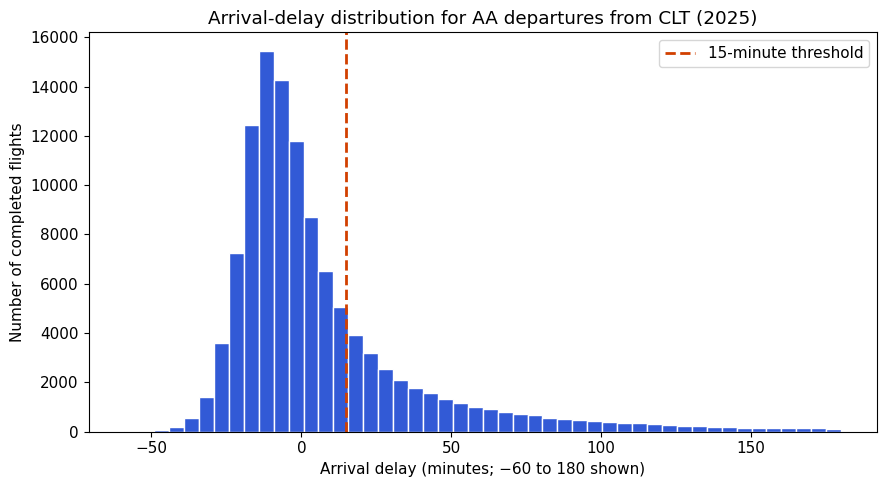

In [4]:
fig, ax = plt.subplots()
display_delays = model_df.loc[model_df["ARR_DELAY"].between(-60, 180), "ARR_DELAY"]
ax.hist(display_delays, bins=48, color=AA_BLUE, edgecolor="white")
ax.axvline(15, color=AA_ORANGE, linestyle="--", linewidth=2, label="15-minute threshold")
ax.set(title="Arrival-delay distribution for AA departures from CLT (2025)",
       xlabel="Arrival delay (minutes; −60 to 180 shown)",
       ylabel="Number of completed flights")
ax.legend()
plt.tight_layout()
plt.show()

,flights,average_delay_min,delay_15_rate
DEP_PERIOD,,,
Overnight,570,-1.5,0.105
Morning,36650,-0.4,0.148
Afternoon,37232,12.8,0.279
Evening,41676,19.1,0.333


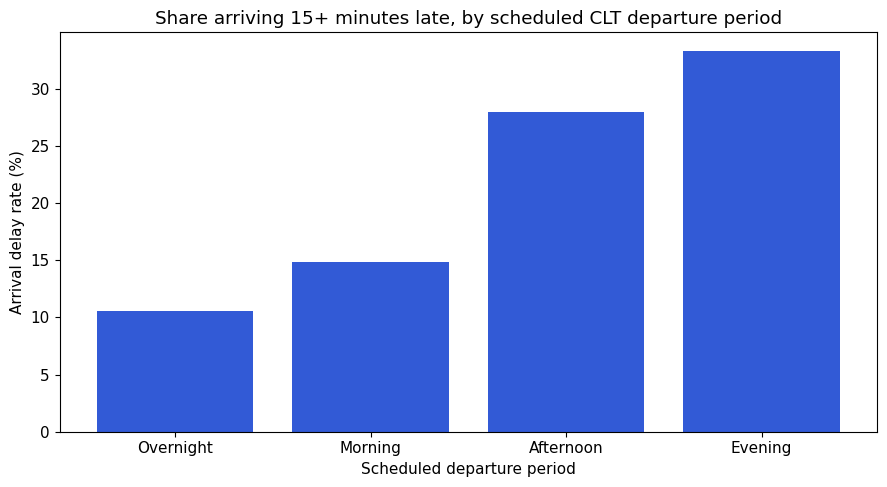

In [5]:
period_summary = (
    model_df.groupby("DEP_PERIOD", observed=True)
    .agg(flights=("ARR_DELAY", "size"),
         average_delay_min=("ARR_DELAY", "mean"),
         delay_15_rate=("ARR_DELAY", lambda x: (x >= 15).mean()))
    .reindex(["Overnight", "Morning", "Afternoon", "Evening"])
)
display(period_summary.round({"average_delay_min": 1, "delay_15_rate": 3}))

fig, ax = plt.subplots()
ax.bar(period_summary.index, 100 * period_summary["delay_15_rate"], color=AA_BLUE)
ax.set(title="Share arriving 15+ minutes late, by scheduled CLT departure period",
       ylabel="Arrival delay rate (%)", xlabel="Scheduled departure period")
plt.tight_layout()
plt.show()

## 5. Time-based train/test split

To reduce overly optimistic results from randomly mixing flights across the year, we use **January–September 2025 for training** and **October–December 2025 for final testing**. This imitates making predictions for later months using earlier records.

We apply **the same training and test flight records** to both models. Results assess association and out-of-time predictive performance, not causation. One calendar year still limits our ability to infer patterns for future years.

In [6]:
train = model_df.loc[model_df["MONTH"] <= 9].copy()
test = model_df.loc[model_df["MONTH"] >= 10].copy()

assert len(train) > 0 and len(test) > 0, "Both train and test periods need flight records."
assert train["FL_DATE"].max() < test["FL_DATE"].min()

y_train, y_test = train["ARR_DELAY"], test["ARR_DELAY"]

print(f"Training: {len(train):,} flights ({train['FL_DATE'].min().date()}–{train['FL_DATE'].max().date()})")
print(f"Testing:  {len(test):,} flights ({test['FL_DATE'].min().date()}–{test['FL_DATE'].max().date()})")
# Group infrequently seen destinations with a training-only rule so unseen
# destinations in Q4 map to OTHER rather than a misleading one-hot reference.
common_destinations = train["DEST"].value_counts()
common_destinations = common_destinations[common_destinations >= 100].index
train["DEST"] = train["DEST"].where(train["DEST"].isin(common_destinations), "OTHER")
test["DEST"] = test["DEST"].where(test["DEST"].isin(common_destinations), "OTHER")
print(f"Destination groups in model: {train['DEST'].nunique()} (including OTHER)")
print("Unknown test categories after grouping:", sorted(set(test["DEST"]) - set(train["DEST"])))

Training: 87,171 flights (2025-01-01–2025-09-30)
Testing:  28,957 flights (2025-10-01–2025-12-31)
Destination groups in model: 86 (including OTHER)
Unknown test categories after grouping: []


## 6. Fit and compare two linear regressions

We use a `Pipeline` to encode categorical variables using **training data only** and to apply the same transformation to the later test set. Our linear regressions predict **arrival-delay minutes**.

| Specification | Features | Interpretation |
|---|---|---|
| **Baseline** | Training-set mean delay | How well can we do without predictors? |
| **Schedule model** | Destination, departure period, weekday, cyclic month | Associations using predeparture information |
| **Operational model** | All schedule features **plus** departure delay and taxi-out minutes | Additional explanatory value after observing operations |

**Why no distance or scheduled duration?** With every flight departing CLT, destination largely determines distance and strongly influences scheduled duration. Including all three could make coefficients unstable and lead to misleading feature-importance rankings. This model uses destination to represent the route. To reduce noise from rare or previously unseen destinations, we group airports with fewer than 100 training flights into `OTHER` using **training data only**.

In [7]:
def regression_model(numeric_features):
    preprocessor = ColumnTransformer(
        transformers=[
            ("categories", OneHotEncoder(handle_unknown="ignore", drop="first"), categorical),
            ("minutes", "passthrough", numeric_features),
        ]
    )
    return Pipeline([
        ("prepare", preprocessor),
        ("regression", LinearRegression()),
    ])

schedule_features = categorical + scheduled_numeric
all_features = categorical + scheduled_numeric + operational_numeric

schedule_model = regression_model(scheduled_numeric)
operational_model = regression_model(scheduled_numeric + operational_numeric)

schedule_model.fit(train[schedule_features], y_train)
operational_model.fit(train[all_features], y_train)

predictions = {
    "No-feature baseline": np.full(len(test), y_train.mean()),
    "Schedule only": schedule_model.predict(test[schedule_features]),
    "Schedule + operations": operational_model.predict(test[all_features]),
}

def score_predictions(y_true, y_pred):
    return {
        "MAE (min)": mean_absolute_error(y_true, y_pred),
        "RMSE (min)": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R²": r2_score(y_true, y_pred),
    }

model_results = pd.DataFrame({
    name: score_predictions(y_test, pred)
    for name, pred in predictions.items()
}).T

display(model_results.round(3))
print("Lower MAE/RMSE is better; higher R² is better.")

,MAE (min),RMSE (min),R²
No-feature baseline,28.612,47.733,-0.014
Schedule only,24.226,47.103,0.012
Schedule + operations,7.021,9.940,0.956


Lower MAE/RMSE is better; higher R² is better.


### Reading the model comparison

- **MAE** is the average absolute prediction error in minutes. This is easy to explain to management.
- **RMSE** penalizes very large prediction errors more heavily.
- **R²** is the share of test-set variance explained relative to a constant prediction based on the test-set mean; a negative R² means worse than that reference.

Expect the operational model to improve fit because `DEP_DELAY` is closely linked to eventual arrival delay. **Do not present that improvement as proof that we have identified root causes**—it partly reflects knowing a flight has already left late.

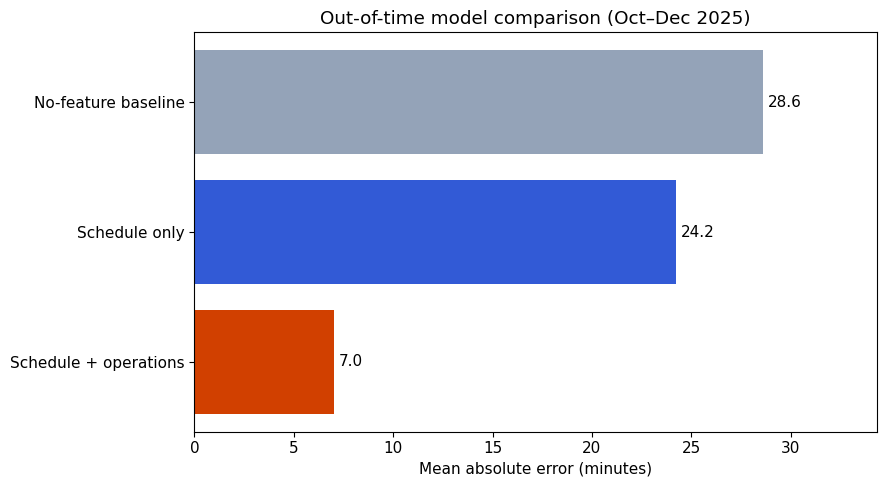

In [8]:
fig, ax = plt.subplots()
ax.barh(model_results.index[::-1], model_results.loc[model_results.index[::-1], "MAE (min)"],
        color=[AA_ORANGE, AA_BLUE, "#94A3B8"])
ax.set(title="Out-of-time model comparison (Oct–Dec 2025)", xlabel="Mean absolute error (minutes)")
for i, value in enumerate(model_results.loc[model_results.index[::-1], "MAE (min)"]):
    ax.text(value + 0.25, i, f"{value:.1f}", va="center")
ax.set_xlim(0, model_results["MAE (min)"].max() * 1.20)
plt.tight_layout()
plt.show()

## 7. Identify the largest conditional associations

**Coefficient interpretation (operational model):** For the numeric predictors, a coefficient represents the predicted change in **arrival-delay minutes** associated with a one-unit change, **holding the other model variables constant**. For example, a `DEP_DELAY` coefficient of 0.8 would correspond to 0.8 additional arrival-delay minutes per additional departure-delay minute, *conditional on the other predictors*.

Coefficients should **not** be compared by absolute size when predictors have different units. The permutation analysis below provides a common-scale ranking by change in test MAE. Destination and departure-period coefficients are encoded as differences relative to an omitted reference category, and should not be interpreted as causal effects.

In [9]:
encoded_names = operational_model.named_steps["prepare"].get_feature_names_out()
weights = pd.Series(
    operational_model.named_steps["regression"].coef_,
    index=encoded_names,
    name="Coefficient (arrival-delay minutes per unit)",
)

numeric_coefficients = weights.loc[
    [f"minutes__{col}" for col in scheduled_numeric + operational_numeric]
].rename(index=lambda name: name.replace("minutes__", ""))

display(numeric_coefficients.to_frame().round(3))
print("Note: sine/cosine season variables are joint cyclic effects, not standalone month effects.")
print("Important: DEP_DELAY and ARR_DELAY share an accounting relationship; its coefficient is not a causal estimate.")

,Coefficient (arrival-delay minutes per unit)
MONTH_SIN,1.418
MONTH_COS,-1.452
DEP_DELAY,1.003
TAXI_OUT,1.018


Note: sine/cosine season variables are joint cyclic effects, not standalone month effects.
Important: DEP_DELAY and ARR_DELAY share an accounting relationship; its coefficient is not a causal estimate.


### Model feature importance: shuffle one group at a time

We measure how much the **operational model's test MAE increases** when we shuffle one original predictor group while holding the other columns fixed. Bigger increases mean the model relied more heavily on that information **for test-set predictions**.

This is a *predictive importance* measure, not evidence of causal influence. Correlated features can share predictive information, so importance can be understated or redistributed among them. We use a reproducible sample for speed.

,Feature group,Change in test MAE (min)
0,Departure delay,25.49
1,Taxi-out time,3.99
2,Destination,0.29
3,Departure period,0.16
5,Season (month),0.02
4,Day of week,0.01


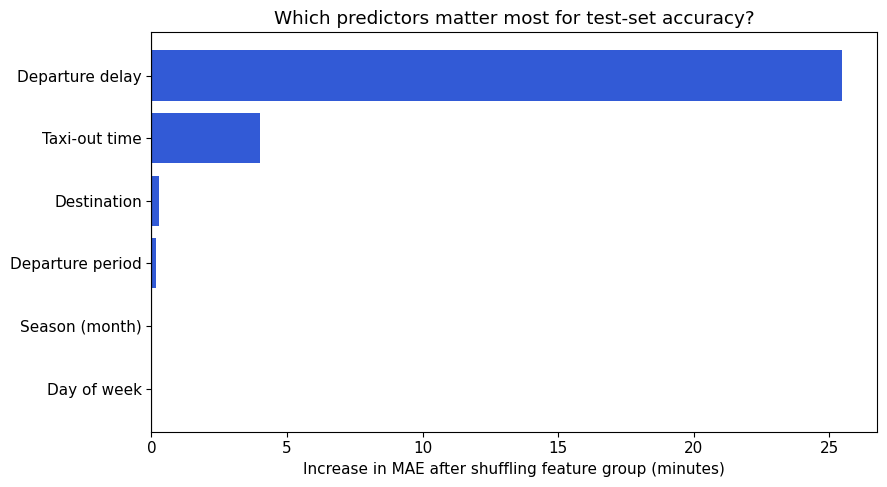

In [10]:
# Work on a reproducible sample to make permutation testing fast.
test_sample = test.sample(n=min(12000, len(test)), random_state=42)
y_sample = test_sample["ARR_DELAY"]
original_mae = mean_absolute_error(
    y_sample, operational_model.predict(test_sample[all_features])
)

feature_groups = {
    "Departure delay": ["DEP_DELAY"],
    "Taxi-out time": ["TAXI_OUT"],
    "Destination": ["DEST"],
    "Departure period": ["DEP_PERIOD"],
    "Day of week": ["WEEKDAY"],
    "Season (month)": ["MONTH_SIN", "MONTH_COS"],
}

rng = np.random.default_rng(42)
importance_rows = []

for label, columns in feature_groups.items():
    increases = []
    for _ in range(3):
        shuffled = test_sample[all_features].copy()
        order = rng.permutation(len(shuffled))
        # Shuffle the season sine/cosine columns together to preserve month pairs.
        shuffled.loc[:, columns] = shuffled[columns].iloc[order].to_numpy()
        shifted_mae = mean_absolute_error(
            y_sample, operational_model.predict(shuffled)
        )
        increases.append(shifted_mae - original_mae)
    importance_rows.append({
        "Feature group": label,
        "Change in test MAE (min)": np.mean(increases),
    })

importance = pd.DataFrame(importance_rows).sort_values(
    "Change in test MAE (min)", ascending=False
)
display(importance.round(2))

fig, ax = plt.subplots()
ordered = importance.sort_values("Change in test MAE (min)")
ax.barh(ordered["Feature group"], ordered["Change in test MAE (min)"], color=AA_BLUE)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Which predictors matter most for test-set accuracy?",
       xlabel="Increase in MAE after shuffling feature group (minutes)")
plt.tight_layout()
plt.show()

## 8. Regression diagnostics

We inspect **prediction errors**, not only a single accuracy statistic. Rare extreme delays can dominate RMSE and cause a linear model to underpredict the tail. We should acknowledge that instead of discarding difficult flights without explanation.

,ARR_DELAY,PREDICTED_DELAY,RESIDUAL
count,28957.00,28957.00,28957.00
mean,6.57,6.24,0.33
std,47.40,46.53,9.93
min,-55.00,-35.32,-41.31
25%,-15.00,-14.54,-5.56
50%,-6.00,-7.67,-0.57
75%,11.00,8.17,4.84
max,948.00,924.70,125.14


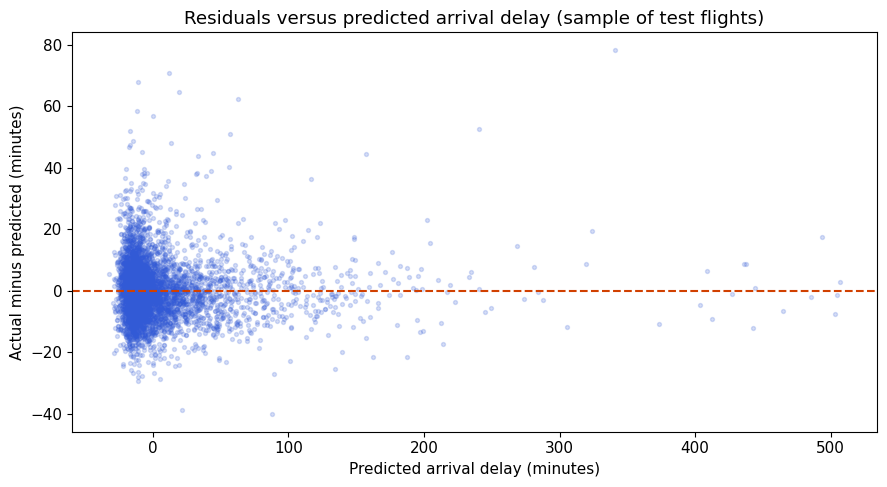

In [11]:
test_diagnostics = test[["FL_DATE", "MONTH", "DEST", "DEP_PERIOD", "ARR_DELAY"]].copy()
test_diagnostics["PREDICTED_DELAY"] = predictions["Schedule + operations"]
test_diagnostics["RESIDUAL"] = (
    test_diagnostics["ARR_DELAY"] - test_diagnostics["PREDICTED_DELAY"]
)

display(test_diagnostics[["ARR_DELAY", "PREDICTED_DELAY", "RESIDUAL"]].describe().round(2))

plot_sample = test_diagnostics.sample(n=min(5000, len(test_diagnostics)), random_state=42)
fig, ax = plt.subplots()
ax.scatter(plot_sample["PREDICTED_DELAY"], plot_sample["RESIDUAL"],
           s=8, alpha=0.20, color=AA_BLUE)
ax.axhline(0, color=AA_ORANGE, linestyle="--")
ax.set(title="Residuals versus predicted arrival delay (sample of test flights)",
       xlabel="Predicted arrival delay (minutes)",
       ylabel="Actual minus predicted (minutes)")
plt.tight_layout()
plt.show()

In [12]:
# Check where model accuracy is worse in the held-out months.
errors_by_month = (
    test_diagnostics.assign(ABS_ERROR=lambda x: x["RESIDUAL"].abs())
    .groupby("MONTH")
    .agg(flights=("ABS_ERROR", "size"), MAE_min=("ABS_ERROR", "mean"))
)
display(errors_by_month.round(2))

# Compare accuracy by departure period, ignoring very sparse groups for discussion.
errors_by_period = (
    test_diagnostics.assign(ABS_ERROR=lambda x: x["RESIDUAL"].abs())
    .groupby("DEP_PERIOD")
    .agg(flights=("ABS_ERROR", "size"), MAE_min=("ABS_ERROR", "mean"))
    .sort_values("MAE_min", ascending=False)
)
display(errors_by_period.round(2))

,flights,MAE_min
MONTH,,
10,10176,7.17
11,9473,6.69
12,9308,7.20


,flights,MAE_min
DEP_PERIOD,,
Overnight,180,7.83
Evening,10167,7.24
Morning,8913,7.21
Afternoon,9697,6.59


## 9. Sensitivity check: do extreme delays change the model?

A small number of flights have very large delays. To assess how sensitive our **estimated coefficients and predictive performance** are to those training observations, we fit the same operational specification again after excluding the highest 1% of training arrival delays.

The **test set stays unchanged** so that both models are evaluated on exactly the same later flights. The trimmed model is a robustness check, **not** the automatically preferred model; extreme delays are real business outcomes.

In [13]:
upper_99 = y_train.quantile(0.99)
trimmed_train = train.loc[train["ARR_DELAY"] <= upper_99]

trimmed_model = regression_model(scheduled_numeric + operational_numeric)
trimmed_model.fit(trimmed_train[all_features], trimmed_train["ARR_DELAY"])

full_pred = predictions["Schedule + operations"]
trimmed_pred = trimmed_model.predict(test[all_features])
sensitivity = pd.DataFrame({
    "All training delays": score_predictions(y_test, full_pred),
    "Train without highest 1%": score_predictions(y_test, trimmed_pred),
}).T

print(f"99th percentile of training arrival delays: {upper_99:.1f} minutes")
print(f"Training records excluded in sensitivity fit: {len(train) - len(trimmed_train):,}")
display(sensitivity.round(3))

trim_weights = pd.Series(
    trimmed_model.named_steps["regression"].coef_,
    index=trimmed_model.named_steps["prepare"].get_feature_names_out(),
)
compare_coefficients = pd.DataFrame({
    "Full data": weights.loc[["minutes__DEP_DELAY", "minutes__TAXI_OUT"]].to_numpy(),
    "Trimmed training": trim_weights.loc[["minutes__DEP_DELAY", "minutes__TAXI_OUT"]].to_numpy(),
}, index=["DEP_DELAY", "TAXI_OUT"])
display(compare_coefficients.round(3))

99th percentile of training arrival delays: 219.0 minutes
Training records excluded in sensitivity fit: 870


,MAE (min),RMSE (min),R²
All training delays,7.021,9.940,0.956
Train without highest 1%,7.017,9.944,0.956


,Full data,Trimmed training
DEP_DELAY,1.003,1.001
TAXI_OUT,1.018,1.010


## 10. Presentation-ready findings and responsible interpretation

Run all cells, then **replace any placeholder statements on your group's Slide 7** with the measured results below. Do not claim that a variable is a controllable root cause just because its coefficient or importance is large.

In [14]:
print("RO2 SUMMARY — AA-OPERATED DEPARTURES FROM CLT, 2025")
print("=" * 58)
print(f"Completed flights used in regression: {len(model_df):,}")
print(f"Train/test: {len(train):,} Jan–Sep / {len(test):,} Oct–Dec")
print()
for model_name in ["No-feature baseline", "Schedule only", "Schedule + operations"]:
    row = model_results.loc[model_name]
    print(f"{model_name}: MAE={row['MAE (min)']:.2f} min, "
          f"RMSE={row['RMSE (min)']:.2f} min, R²={row['R²']:.3f}")
print()
for name in ["DEP_DELAY", "TAXI_OUT"]:
    print(f"Conditional coefficient — {name}: {numeric_coefficients[name]:+.3f} "
          "arrival-delay minutes per minute")
print()
print("Top 3 features by test-set permutation importance:")
for _, row in importance.head(3).iterrows():
    print(f"  {row['Feature group']}: +{row['Change in test MAE (min)']:.2f} MAE minutes")
print()
print("Caution: Associations are observational; operational variables are observed during/after departure.")

RO2 SUMMARY — AA-OPERATED DEPARTURES FROM CLT, 2025
Completed flights used in regression: 116,128
Train/test: 87,171 Jan–Sep / 28,957 Oct–Dec

No-feature baseline: MAE=28.61 min, RMSE=47.73 min, R²=-0.014
Schedule only: MAE=24.23 min, RMSE=47.10 min, R²=0.012
Schedule + operations: MAE=7.02 min, RMSE=9.94 min, R²=0.956

Conditional coefficient — DEP_DELAY: +1.003 arrival-delay minutes per minute
Conditional coefficient — TAXI_OUT: +1.018 arrival-delay minutes per minute

Top 3 features by test-set permutation importance:
  Departure delay: +25.49 MAE minutes
  Taxi-out time: +3.99 MAE minutes
  Destination: +0.29 MAE minutes

Caution: Associations are observational; operational variables are observed during/after departure.


## 11. What the team can—and cannot—recommend

**Supported by this notebook:**
- Which planned-flight characteristics are associated with arrival delays for flights departing CLT.
- How much additional explanatory / predictive accuracy is gained when actual departure delay and taxi-out time are available. Because arrival delay is mathematically related to departure delay and the difference between actual and scheduled flight duration, a strong `DEP_DELAY` coefficient is partly **mechanical**, not a new causal discovery.
- Which feature groups the trained model relies on most, measured on held-out later flights.
- Whether conclusions are sensitive to the longest delays.

**Not established by these regressions alone:**
- That delays originate specifically at a CLT gate or taxiway.
- That adjusting gate buffers or taxi sequencing would *cause* a specific reduction in delays.
- That weather, NAS, carrier, or late-aircraft delay-cause minutes are valid predictors available before arrival. Those BTS categories are reported following operational disruptions and should be analyzed separately for context (RO1/additional findings).
- The effect on passenger connections or cost; those outcomes are not directly measured in this dataset.

**Actionable next step:** Use this analysis alongside RO1 destination/time comparisons and RO3 route clustering to select candidates for **operational investigation or pilots**, then evaluate the changes with a properly defined comparison group.

**Source:** BTS Reporting Carrier On-Time Performance, January–December 2025; filtered to `OP_CARRIER == 'AA'`, `ORIGIN == 'CLT'` for this regression. The master file retains AA-operated flights both arriving at and departing from CLT.